# **Assignment 6**

**PART A:** **Inverse Problem: Diffusion-Reaction**

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import RegularGridInterpolator

torch.manual_seed(0)
np.random.seed(0)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

# Problem setup: u_t = D*u_xx - k*u, x in [0,1], t in [0,1]
# D = 0.001 (known), k = 0.01 (unknown -> to recover)
# IC: u(x,0) = sin(pi x)   BC: u(0,t) = u(1,t) = 0
D_true = 0.001
k_true = 0.01

Using device: cpu


This is "method of lines": space is discretized into a grid (finite differences for u_xx), and solve ivp handles the time integration with an adaptive RK45 solver, which is more accurate than a fixed step explicit scheme. Only interior points are integrated, the boundary points are just left at 0 the whole time, which is how the Dirichlet BC u(0,t)=u(1,t)=0 gets enforced without any extra code. The analytic check (U analytic) is a nice to have, not required by the assignment, but it confirms the FD solver is actually correct (error 1e-8) before you trust it as "ground truth" for the inverse problem.


In [2]:
Nx = 201
x_grid = np.linspace(0, 1, Nx)
dx = x_grid[1] - x_grid[0]
x_int = x_grid[1:-1]                     # interior points (BC fixes ends at 0)

def rhs(t, u_int):
    u_full = np.zeros(Nx)
    u_full[1:-1] = u_int
    u_xx = (u_full[2:] - 2 * u_full[1:-1] + u_full[:-2]) / dx**2
    return D_true * u_xx - k_true * u_int

u0_int = np.sin(np.pi * x_int)
t_eval = np.linspace(0, 1, 201)

sol = solve_ivp(rhs, [0, 1], u0_int, t_eval=t_eval,
                 method='RK45', rtol=1e-8, atol=1e-10)

U = np.zeros((len(t_eval), Nx))
U[:, 1:-1] = sol.y.T                     # boundaries stay 0

# sanity check vs analytic solution (valid for this IC/BC):
# u(x,t) = exp(-(D*pi^2 + k) t) * sin(pi x)
U_analytic = (np.exp(-(D_true * np.pi**2 + k_true) * t_eval)[:, None]
              * np.sin(np.pi * x_grid)[None, :])
print('max |FD - analytic| =', np.abs(U - U_analytic).max())

max |FD - analytic| = 1.9972606968288176e-07


Purely diagnostic, not a deliverable. Useful to eyeball that the solution decays smoothly and doesn't do anything numerically weird (oscillate) before you build observations from it.

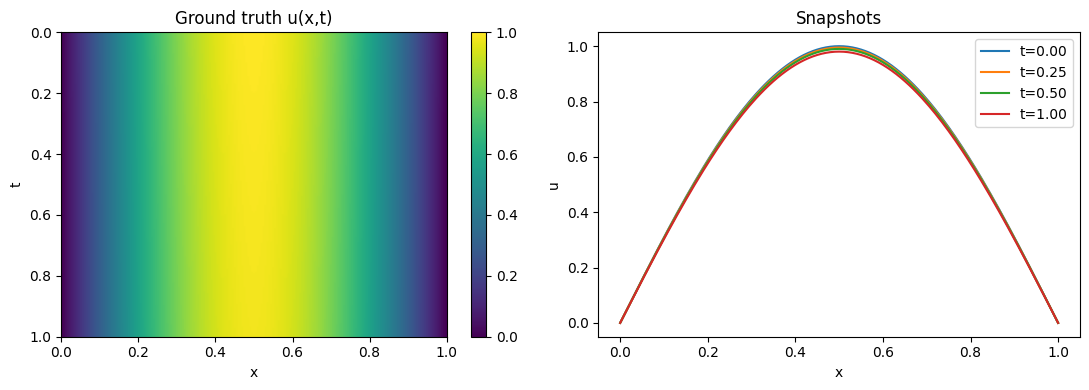

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(U, extent=[0, 1, 1, 0], aspect='auto', cmap='viridis')
ax[0].set_xlabel('x'); ax[0].set_ylabel('t'); ax[0].set_title('Ground truth u(x,t)')
plt.colorbar(im, ax=ax[0])

for frac in [0.0, 0.25, 0.5, 1.0]:
    idx = int(frac * (len(t_eval) - 1))
    ax[1].plot(x_grid, U[idx], label=f't={t_eval[idx]:.2f}')
ax[1].set_xlabel('x'); ax[1].set_ylabel('u'); ax[1].legend(); ax[1].set_title('Snapshots')
plt.tight_layout()
plt.show()

RegularGridInterpolator lets you pull u at arbitrary (x,t) points instead of being restricted to the solver's grid, this is what makes the observations "random" rather than grid-aligned, closer to how real sensor data would look. Noise is scaled as a fraction of u_obs_clean.std() rather than a fixed absolute number, this is what "1% noise" and "5% noise" actually mean in the assignment (percentage of the signal's spread, not of each individual value). obs by noise precomputes all three noisy datasets up front so the noise realization is fixed once and reused, rather than being redrawn every time you touch it.

In [4]:
interp = RegularGridInterpolator((t_eval, x_grid), U)

N_obs = 100
x_obs = np.random.uniform(0, 1, N_obs)
t_obs = np.random.uniform(0, 1, N_obs)
u_obs_clean = interp(np.stack([t_obs, x_obs], axis=1))

def make_noisy_obs(sigma_frac, seed=0):
    rng = np.random.default_rng(seed)
    noise_std = sigma_frac * u_obs_clean.std()
    return u_obs_clean + rng.normal(0, noise_std, size=u_obs_clean.shape)

noise_levels = [0.0, 0.01, 0.05]                       # 0%, 1%, 5%
obs_by_noise = {s: make_noisy_obs(s) for s in noise_levels}
print('Observation std (clean):', u_obs_clean.std())

Observation std (clean): 0.3128394308005247


A plain MLP taking (x,t) to u, with Tanh activations, the standard choice for PINNs because it's smooth and infinitely differentiable, which matters since you're about to take derivatives of the network's output up to second order (u_xx). ReLU would break this (its second derivative is zero almost everywhere). The layers tuple makes width/depth easy to tune if training is too slow or not accurate enough.

In [5]:
class PINN(nn.Module):
    def __init__(self, layers=(2, 32, 32, 32, 32, 1)):
        super().__init__()
        mods = []
        for i in range(len(layers) - 2):
            mods.append(nn.Linear(layers[i], layers[i + 1]))
            mods.append(nn.Tanh())
        mods.append(nn.Linear(layers[-2], layers[-1]))
        self.net = nn.Sequential(*mods)

    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=1))

This is where the "inverse" part actually happens: k_hat is declared as an nn.Parameter and added to the same optimizer as the network weights, so gradient descent updates the network and the unknown physical constant simultaneously. create graph=True in the autograd.grad calls is essential, it's what allows you to differentiate through the already computed gradient again (needed to get u_xx, a second derivative, and to backpropagate through Lpde into k_hat). The four loss terms map directly onto the assignment's formula L = L_pde + L_data + L_ic + L_bc: PDE residual on random collocation points (not the same as the observation points, this is what lets the model generalize across the whole domain, not just memorize the 100 samples), data mismatch at the noisy observations, and IC/BC terms that pin down the solution's shape independent of any observed data. Printing k_hat every 500 epochs lets you visually confirm convergence rather than trusting the final number blindly.

In [6]:
def train_pinn(u_obs_noisy, x_obs, t_obs, D=D_true, k_init=0.1,
               n_colloc=1500, n_ic=100, n_bc=100, epochs=3000, lr=2e-3):

    model = PINN().to(device)
    k_hat = nn.Parameter(torch.tensor([k_init], dtype=torch.float32, device=device))
    optimizer = torch.optim.Adam(list(model.parameters()) + [k_hat], lr=lr)

    x_obs_t = torch.tensor(x_obs, dtype=torch.float32, device=device).view(-1, 1)
    t_obs_t = torch.tensor(t_obs, dtype=torch.float32, device=device).view(-1, 1)
    u_obs_t = torch.tensor(u_obs_noisy, dtype=torch.float32, device=device).view(-1, 1)

    # IC / BC supervision points (fixed by the problem statement, not "data")
    x_ic = torch.rand(n_ic, 1, device=device)
    t_ic = torch.zeros(n_ic, 1, device=device)
    u_ic = torch.sin(np.pi * x_ic)

    t_bc = torch.rand(n_bc, 1, device=device)
    x_bc0 = torch.zeros(n_bc, 1, device=device)
    x_bc1 = torch.ones(n_bc, 1, device=device)

    for ep in range(epochs):
        optimizer.zero_grad()

        # PDE residual at random collocation points
        x_c = torch.rand(n_colloc, 1, device=device, requires_grad=True)
        t_c = torch.rand(n_colloc, 1, device=device, requires_grad=True)
        u_c = model(x_c, t_c)

        u_t = torch.autograd.grad(u_c, t_c, grad_outputs=torch.ones_like(u_c),
                                   create_graph=True)[0]
        u_x = torch.autograd.grad(u_c, x_c, grad_outputs=torch.ones_like(u_c),
                                   create_graph=True)[0]
        u_xx = torch.autograd.grad(u_x, x_c, grad_outputs=torch.ones_like(u_x),
                                    create_graph=True)[0]

        res = u_t - D * u_xx + k_hat * u_c
        L_pde = (res ** 2).mean()

        # data loss
        u_pred_obs = model(x_obs_t, t_obs_t)
        L_data = ((u_pred_obs - u_obs_t) ** 2).mean()

        # IC loss
        L_ic = ((model(x_ic, t_ic) - u_ic) ** 2).mean()

        # BC loss
        L_bc = (model(x_bc0, t_bc) ** 2).mean() + (model(x_bc1, t_bc) ** 2).mean()

        loss = L_pde + L_data + L_ic + L_bc
        loss.backward()
        optimizer.step()

        if ep % 500 == 0:
            print(f'  epoch {ep:5d}  loss={loss.item():.3e}  k_hat={k_hat.item():.5f}')

    return model, k_hat.item()

Just loops the same training routine over the three noise levels and stores each recovered k. Each call starts from a fresh untrained model and kinit=0.1,  this matters because it means each noise level is a fair, independent test of recovery, not warm-started from the previous run's answer.

In [7]:
results = {}
for sigma in noise_levels:
    print(f'--- training with noise level {sigma*100:.0f}% ---')
    u_noisy = obs_by_noise[sigma]
    model, k_hat = train_pinn(u_noisy, x_obs, t_obs, k_init=0.1, epochs=3000)
    results[sigma] = k_hat
    print(f'  recovered k = {k_hat:.5f}   (true k = {k_true})\n')

--- training with noise level 0% ---
  epoch     0  loss=1.599e+00  k_hat=0.10200
  epoch   500  loss=1.795e-04  k_hat=0.02481
  epoch  1000  loss=4.516e-05  k_hat=0.01247
  epoch  1500  loss=3.295e-05  k_hat=0.01099
  epoch  2000  loss=2.503e-05  k_hat=0.01063
  epoch  2500  loss=1.142e-04  k_hat=0.01054
  recovered k = 0.01037   (true k = 0.01)

--- training with noise level 1% ---
  epoch     0  loss=7.447e-01  k_hat=0.10200
  epoch   500  loss=1.830e-03  k_hat=0.03271
  epoch  1000  loss=7.420e-04  k_hat=0.01233
  epoch  1500  loss=6.491e-05  k_hat=0.01134
  epoch  2000  loss=2.602e-04  k_hat=0.01189
  epoch  2500  loss=2.254e-03  k_hat=0.01087
  recovered k = 0.01041   (true k = 0.01)

--- training with noise level 5% ---
  epoch     0  loss=1.260e+00  k_hat=0.09800
  epoch   500  loss=1.828e-03  k_hat=0.02176
  epoch  1000  loss=2.747e-04  k_hat=0.01298
  epoch  1500  loss=4.154e-04  k_hat=0.01120
  epoch  2000  loss=2.496e-04  k_hat=0.01072
  epoch  2500  loss=2.462e-04  k_hat=0

Straightforward, but the dashed horizontal line at ktrue is what the assignment explicitly asks for, it turns the plot from "here are three numbers" into a visual you can immediately judge accuracy from at a glance.

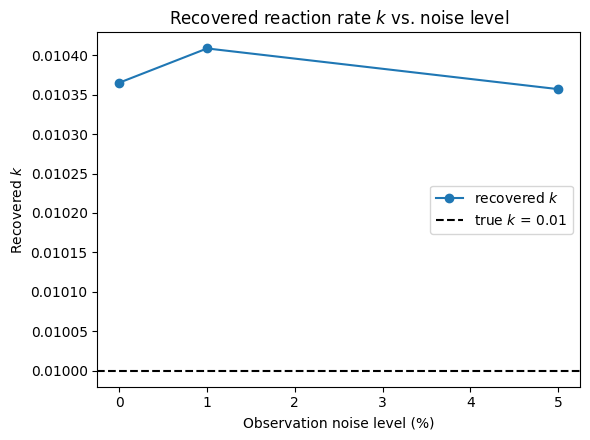

In [8]:
sigmas_pct = [s * 100 for s in noise_levels]
k_hats = [results[s] for s in noise_levels]
rel_err = [abs(k_hats[i] - k_true) / k_true * 100 for i in range(len(noise_levels))]

plt.figure(figsize=(6, 4.5))
plt.plot(sigmas_pct, k_hats, 'o-', color='tab:blue', label='recovered $k$')
plt.axhline(k_true, ls='--', color='k', label=f'true $k$ = {k_true}')
plt.xlabel('Observation noise level (%)')
plt.ylabel('Recovered $k$')
plt.title('Recovered reaction rate $k$ vs. noise level')
plt.legend()
plt.tight_layout()
plt.savefig('k_vs_noise.png', dpi=150)
plt.show()

Formats the same numbers as the second explicitly requested deliverable. Relative error (|k_hat - ktrue| / ktrue) is the more meaningful metric than absolute error here, since ktrue = 0.01 is small, a raw absolute error of 0.0003 sounds tiny but is actually a 3% miss, which the table makes clear.


In [9]:
print(f"{'Noise level':>12} | {'Recovered k':>13} | {'Relative error':>15}")
print('-' * 46)
for s, kh, re in zip(sigmas_pct, k_hats, rel_err):
    print(f"{s:>10.0f} % | {kh:>13.5f} | {re:>13.2f} %")

 Noise level |   Recovered k |  Relative error
----------------------------------------------
         0 % |       0.01037 |          3.65 %
         1 % |       0.01041 |          4.09 %
         5 % |       0.01036 |          3.57 %


**PART B:  Track Proposal**

Section 1: Track chosen
Track B — Fluid Dynamics / Navier–Stokes


# Section 2: Project description
For my project I want to work on 2D incompressible Navier–Stokes flow around a cylinder, specifically the data assimilation angle rather than solving NS forward from scratch. The idea is that instead of giving the PINN the full velocity field to learn from, I'll only give it a small number of sparse sensor readings and see how well it can reconstruct the entire flow, both velocity (u, v) and pressure p, just from those few points plus the physics itself.
This is really the same hybrid loss trick from this week's diffusion-reaction assignment, just scaled up and instead of one scalar field and one unknown constant, I now have three coupled fields and a divergence-free constraint on top. The loss will combine the PDE residuals (continuity + x-momentum + y-momentum), boundary conditions, and the sparse data fit.
What I'll actually build:

A PyTorch NS-PINN where the network maps (x, y, t) → [u, v, p], trained on L = L_continuity + L_x_momentum + L_y_momentum + L_bc + L_data.
I'll use the ns_unsteady_cylinder case from jaxpi as my reference setup (or fall back to the simpler PyTorch NS-PINN repo if jaxpi is a pain to get running), mainly for the geometry and reference flow data, not necessarily their exact training code.
Then I'll deliberately throw away most of the velocity data and only keep Nsensors ∈ {10, 50, 200} points, retraining at each level to see how the reconstruction degrades.

What I expect to come out of this: ideally, a PINN that can recover the full vortex-shedding pattern behind the cylinder from somewhere around 50 sensors  and pressure comes along for free, since it's never observed directly, only inferred through the momentum equations. I want to end up with an L² reconstruction error vs. sensor count plot, and figure out roughly where the reconstruction starts to fall apart i.e., the minimum number of sensors that still gives you a recognizable vortex-shedding pattern.

# Section 3: Reading plan (Week 7)

NSFnets (Jin, Cai, Li, Karniadakis, 2021) arXiv:2003.06496. This is basically the reference paper for how to set up an NS-PINN properly, so I want to read it in full before I start coding anything.
Hidden Fluid Mechanics (Raissi, Yazdani, Karniadakis, Science 2020) arXiv:1808.04327. Reading this properly as a fluids paper this time (we only skimmed the intro in Week 6) since it's the closest thing to a template for what I'm trying to do with sparse sensors.
PINNs for fluid mechanics: a review (Cai, Mao, Wang, Yin, Karniadakis, 2021) — arXiv:2105.09506. Mostly to get a sense of what's actually realistic to pull off in two weeks before I commit to a scope.